# Nº 09 · Descente stochastique et mini-lots

*θ Théta, le Machine Learning, une notion à la fois.*

Le gradient complet lit toutes les données à chaque pas. Un mini-lot n'en lit qu'une partie : le pas est moins
précis, mais beaucoup moins coûteux. On compare les trois variantes sur les ventes d'Ames.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

LOCAL = Path("donnees/ames-maisons.csv.gz")
ORIGINE = "http://jse.amstat.org/v19n3/decock/AmesHousing.txt"

ventes = pd.read_csv(LOCAL) if LOCAL.exists() else pd.read_csv(ORIGINE, sep="\t")
ventes = ventes[ventes["Gr Liv Area"] <= 4000]
x = ventes["Gr Liv Area"].to_numpy() * 0.09290304 / 100
y = ventes["SalePrice"].to_numpy() * 588.30 / 1e6
n = len(x)

## 1. Combien de pas par époque ?

Une époque correspond à une lecture de toutes les données. La taille du lot fixe le nombre de pas par époque.

In [2]:
for lot in (n, 256, 32, 1):
    print(f"lot de {lot:>4} : {int(np.ceil(n / lot)):>4} pas par époque")

assert int(np.ceil(n / 32)) == 92

lot de 2925 :    1 pas par époque
lot de  256 :   12 pas par époque
lot de   32 :   92 pas par époque
lot de    1 : 2925 pas par époque


## 2. Une descente, trois tailles de lot

On mélange les données à chaque époque, puis on avance lot après lot. Le budget est le même pour tous :
cinq époques, soit cinq lectures complètes des données.

In [3]:
def mse(w, b):
    return np.mean((w * x + b - y) ** 2)


def entrainer(lot, eta, epoques, graine=0):
    rng = np.random.default_rng(graine)
    w, b = 0.0, 0.0
    couts = [mse(w, b)]
    for _ in range(epoques):
        ordre = rng.permutation(n)
        for debut in range(0, n, lot):
            choix = ordre[debut:debut + lot]
            erreur = w * x[choix] + b - y[choix]
            w -= eta * 2 * np.mean(erreur * x[choix])
            b -= eta * 2 * np.mean(erreur)
            couts.append(mse(w, b))
    return np.array(couts), w, b


resultats = {"gradient complet": entrainer(n, 0.2, 5), "mini-lots de 32": entrainer(32, 0.05, 5),
             "un exemple à la fois": entrainer(1, 0.005, 5)}

for nom, (couts, w, b) in resultats.items():
    print(f"{nom:<22} : {len(couts) - 1:>6} pas, J final = {couts[-1]:,.0f}".replace(",", " "))

gradient complet       :      5 pas  J final = 1 102
mini-lots de 32        :    460 pas  J final = 1 058
un exemple à la fois   :  14625 pas  J final = 1 068


À budget égal, le gradient complet a fait 5 pas. Les mini-lots en ont fait 460 et finissent plus bas.

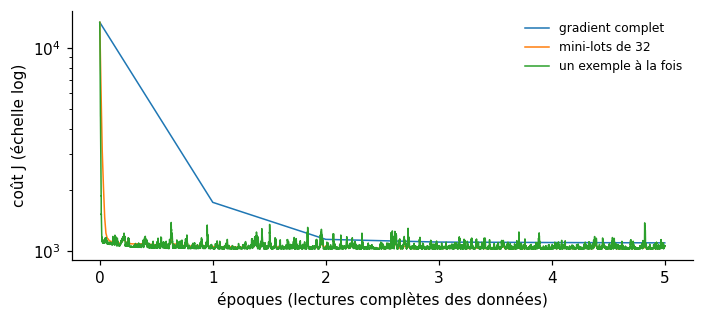

In [4]:
assert resultats["mini-lots de 32"][0][-1] < resultats["gradient complet"][0][-1]

plt.figure(figsize=(6.5, 3))
for nom, (couts, _, _) in resultats.items():
    epoques = np.linspace(0, 5, len(couts))
    plt.semilogy(epoques, couts, label=nom, linewidth=1)
plt.xlabel("époques (lectures complètes des données)")
plt.ylabel("coût J (échelle log)")
plt.legend(frameon=False, fontsize=8)
plt.tight_layout()

## 3. Le prix à payer : le bruit

Avec un η fixe, un petit lot ne se pose pas : le coût oscille près du creux. Réduire η au fil des époques calme
ces oscillations.

In [5]:
def oscillation(lot, eta):
    couts, _, _ = entrainer(lot, eta, 20)
    fin = couts[-len(couts) // 4:]
    return fin.std()


petit, grand = oscillation(4, 0.05), oscillation(256, 0.05)
print(f"oscillation du coût en fin d'entraînement : lot de 4 = {petit:.2f}, lot de 256 = {grand:.2f}")
assert petit > grand

oscillation du coût en fin d'entraînement : lot de 4 = 124.05, lot de 256 = 1.69


## À vous

1. Faites varier la graine : les courbes changent-elles ? Pourquoi ?
2. Divisez η par deux à chaque époque, pour le lot de 4. Que devient l'oscillation ?

**Sources** : Ruder (2016), Deep Learning Book, chapitre 8, D2L. Les références complètes figurent dans le premier
commentaire de l'épisode.